In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load data
data = pd.read_csv("train.csv")
data['date'] = pd.to_datetime(data['date'])

df = data[(data['store'] == 1) & (data['item'] == 1)].copy()
df = df.sort_values('date')

# Time-aware split
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
valid = df.iloc[split_index:]

print("Train size:", len(train))
print("Validation size:", len(valid))


Train size: 1460
Validation size: 366


In [2]:
valid['naive_forecast'] = df['sales'].shift(1).iloc[split_index:]


C:\Users\Siddharth Singh\AppData\Local\Temp\ipykernel_23740\683425042.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid['naive_forecast'] = df['sales'].shift(1).iloc[split_index:]


In [3]:
mae = mean_absolute_error(valid['sales'], valid['naive_forecast'])
rmse = np.sqrt(mean_squared_error(valid['sales'], valid['naive_forecast']))

print("Naive MAE:", mae)
print("Naive RMSE:", rmse)


Naive MAE: 6.297814207650274
Naive RMSE: 7.724597006129435


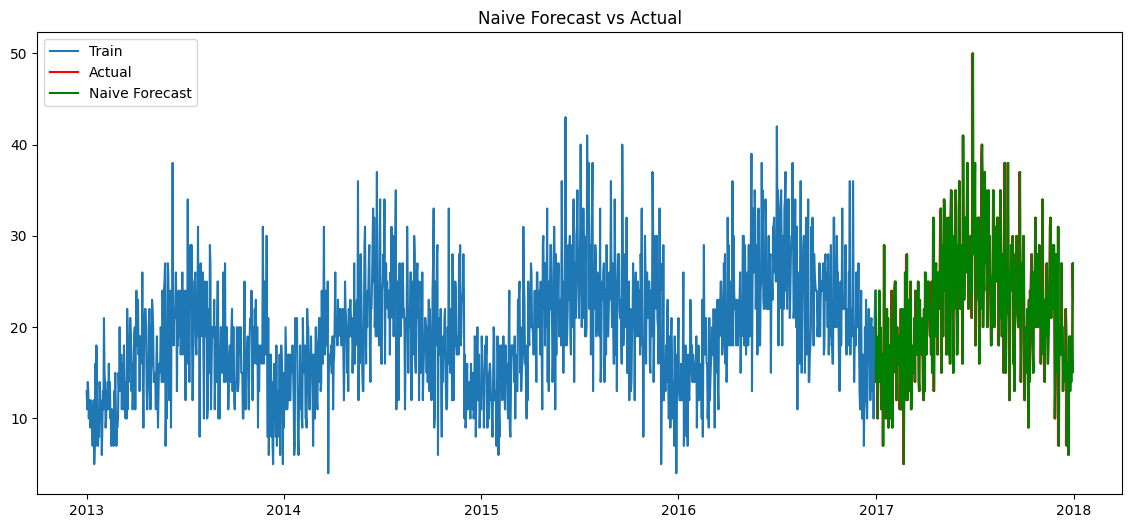

In [8]:
plt.figure(figsize=(14,6))
plt.plot(train['date'], train['sales'], label='Train')
plt.plot(valid['date'], valid['sales'],color='red' ,label='Actual')
plt.plot(valid['date'], valid['naive_forecast'],color='green', label='Naive Forecast')
plt.legend()
plt.title("Naive Forecast vs Actual")
plt.show()
